# PlantVillage Image Augmentation

Build and check a training-only augmentation pipeline using the existing dataset split. The original images and the train/validation/test assignments are left unchanged.

## 1. Setup

In [16]:
from pathlib import Path
import math
import zipfile
import inspect

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
IMG_SIZE = 224
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

np.random.seed(SEED)
tf.random.set_seed(SEED)

SPLIT_CSV = Path("/kaggle/input/datasets/astitvasrivastava05/plantvillage-existing-splits/plantvillage_splits.csv")
COLOR_DIR = Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")
OUTPUT_DIR = Path("/kaggle/working/augmentation_handoff")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Split CSV found:", SPLIT_CSV.is_file())
print("Colour folder found:", COLOR_DIR.is_dir())

TensorFlow: 2.20.0
Split CSV found: True
Colour folder found: True


## 2. Load the split CSV

In [17]:
splits_df = pd.read_csv(SPLIT_CSV)

print(f"Images in split CSV: {len(splits_df):,}")
print(f"Classes: {splits_df['label'].nunique()}")
display(splits_df.head())

Images in split CSV: 54,042
Classes: 38


,image_path,label,split,crop,disease
0,Apple___Apple_scab/00075aa8-d81a-4184-8541-b69...,Apple___Apple_scab,val,Apple,Apple_scab
1,Apple___Apple_scab/01a66316-0e98-4d3b-a56f-d78...,Apple___Apple_scab,val,Apple,Apple_scab
2,Apple___Apple_scab/01f3deaa-6143-4b6c-9c22-620...,Apple___Apple_scab,train,Apple,Apple_scab
3,Apple___Apple_scab/0208f4eb-45a4-4399-904e-989...,Apple___Apple_scab,train,Apple,Apple_scab
4,Apple___Apple_scab/023123cb-7b69-4c9f-a521-766...,Apple___Apple_scab,train,Apple,Apple_scab


## 3. Match CSV paths to the colour images

In [18]:
from pathlib import Path

COLOR_DIR = Path(
    "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
)

splits_df["image_relpath"] = splits_df["image_path"].astype(str)

splits_df["resolved_image_path"] = splits_df["image_relpath"].map(
    lambda path: str(COLOR_DIR / path)
)

missing_paths = [
    path for path in splits_df["resolved_image_path"]
    if not Path(path).is_file()
]

print("Images:", len(splits_df))
print("Missing images:", len(missing_paths))

if missing_paths:
    print("Examples:", missing_paths[:5])
    raise FileNotFoundError("Some CSV image paths could not be found.")

folder_labels = splits_df["image_relpath"].str.split("/").str[0]
label_mismatches = (folder_labels != splits_df["label"]).sum()

print("Label/folder mismatches:", label_mismatches)

if label_mismatches:
    raise ValueError("Some labels do not match their image folders.")

Images: 54042
Missing images: 0
Label/folder mismatches: 0


## 4. Check the existing split

In [19]:
splits_df["split"] = splits_df["split"].astype(str).str.strip().str.lower().replace({"validation": "val", "valid": "val"})

split_counts = splits_df["split"].value_counts().reindex(["train", "val", "test"], fill_value=0)
print(split_counts.to_string())
print(f"Unique image paths: {splits_df['image_relpath'].nunique():,}")
print(f"Classes: {splits_df['label'].nunique()}")

if splits_df["image_relpath"].duplicated().any():
    raise ValueError("Repeated image paths found.")

class_split_counts = pd.crosstab(splits_df["label"], splits_df["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
print("Classes missing from a split:", int((class_split_counts == 0).any(axis=1).sum()))

train_df = splits_df[splits_df["split"] == "train"].reset_index(drop=True)
val_df = splits_df[splits_df["split"] == "val"].reset_index(drop=True)
test_df = splits_df[splits_df["split"] == "test"].reset_index(drop=True)

split
train    37827
val       8107
test      8108
Unique image paths: 54,042
Classes: 38
Classes missing from a split: 0


## 5. Augmentation functions

Rotation is limited to +/-30° normally or +/-40° in strong mode. Brightness ranges from 0.60times to 1.40times, so darkening is included. Blur and noise are applied occasionally, and cutout hides no more than 20% of the image.

In [20]:
def load_rgb_image(path, img_size=IMG_SIZE):
    image = tf.io.read_file(str(path))
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(image, [img_size, img_size], antialias=True)
    image = tf.clip_by_value(image, 0.0, 1.0)
    image.set_shape([img_size, img_size, 3])
    return image


def _rotate_image(image, angle_degrees):
    height, width = tf.shape(image)[0], tf.shape(image)[1]
    angle = tf.cast(angle_degrees, tf.float32) * (math.pi / 180.0)
    cosine, sine = tf.cos(angle), tf.sin(angle)
    cx = (tf.cast(width, tf.float32) - 1.0) / 2.0
    cy = (tf.cast(height, tf.float32) - 1.0) / 2.0
    transform = tf.stack([
        cosine, -sine, cx - cosine * cx + sine * cy,
        sine, cosine, cy - sine * cx - cosine * cy,
        0.0, 0.0,
    ])
    return tf.raw_ops.ImageProjectiveTransformV3(
        images=image[None, ...],
        transforms=tf.reshape(transform, [1, 8]),
        output_shape=tf.stack([height, width]),
        interpolation="BILINEAR",
        fill_mode="REFLECT",
        fill_value=0.0,
    )[0]

In [21]:
MAX_CUTOUT_AREA = 0.20


def _gaussian_blur(image, sigma):
    coords = tf.range(-2, 3, dtype=tf.float32)
    kernel_1d = tf.exp(-(coords ** 2) / (2.0 * sigma ** 2))
    kernel_1d /= tf.reduce_sum(kernel_1d)
    kernel_2d = kernel_1d[:, None] * kernel_1d[None, :]
    kernel = tf.tile(kernel_2d[:, :, None, None], [1, 1, 3, 1])
    return tf.nn.depthwise_conv2d(image[None, ...], kernel, [1, 1, 1, 1], "SAME")[0]


def _random_cutout_mask(height, width, max_area=MAX_CUTOUT_AREA):
    area = tf.random.uniform([], 0.02, max_area) * tf.cast(height * width, tf.float32)
    aspect = tf.random.uniform([], 0.5, 2.0)
    cut_h = tf.clip_by_value(tf.cast(tf.floor(tf.sqrt(area / aspect)), tf.int32), 1, height)
    cut_w = tf.clip_by_value(tf.cast(tf.floor(tf.sqrt(area * aspect)), tf.int32), 1, width)
    y0 = tf.random.uniform([], 0, height - cut_h + 1, dtype=tf.int32)
    x0 = tf.random.uniform([], 0, width - cut_w + 1, dtype=tf.int32)
    ys, xs = tf.range(height)[:, None], tf.range(width)[None, :]
    return (ys >= y0) & (ys < y0 + cut_h) & (xs >= x0) & (xs < x0 + cut_w)


def _apply_cutout(image, max_area=MAX_CUTOUT_AREA):
    height, width = tf.shape(image)[0], tf.shape(image)[1]
    mask = _random_cutout_mask(height, width, max_area)[:, :, None]
    fill = tf.broadcast_to(tf.reduce_mean(image, axis=[0, 1], keepdims=True), tf.shape(image))
    return tf.where(mask, fill, image)


def _maybe(probability, transform, image):
    return tf.cond(tf.random.uniform([]) < probability, lambda: transform(image), lambda: image)

In [22]:
def augment_image(image, strong=False):
    """Applying random augmentation to one RGB float image in [0,1]. Used for training part only."""
    image_shape = image.shape
    image = tf.cast(image, tf.float32)
    strong = tf.convert_to_tensor(strong, dtype=tf.bool)

    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    max_rotation = tf.where(strong, 40.0, 30.0)
    angle = tf.random.uniform([], -max_rotation, max_rotation)
    image = _rotate_image(image, angle)

    image *= tf.random.uniform([], 0.60, 1.40)
    image = tf.image.adjust_contrast(
        tf.clip_by_value(image, 0.0, 1.0),
        tf.random.uniform([], tf.where(strong, 0.75, 0.80), tf.where(strong, 1.25, 1.20)),
    )
    image = tf.image.adjust_saturation(
        tf.clip_by_value(image, 0.0, 1.0),
        tf.random.uniform([], tf.where(strong, 0.75, 0.80), tf.where(strong, 1.25, 1.20)),
    )
    hue_limit = tf.where(strong, 0.03, 0.02)
    image = tf.image.adjust_hue(
        tf.clip_by_value(image, 0.0, 1.0), tf.random.uniform([], -hue_limit, hue_limit)
    )

    image = _maybe(
        tf.where(strong, 0.30, 0.20),
        lambda x: _gaussian_blur(x, tf.random.uniform([], 0.5, 1.2)), image,
    )
    noise_std = tf.where(strong, 0.03, 0.02)
    image = _maybe(
        tf.where(strong, 0.30, 0.20),
        lambda x: x + tf.random.normal(tf.shape(x), stddev=noise_std), image,
    )
    image = _maybe(
        tf.where(strong, 0.35, 0.25),
        lambda x: _apply_cutout(x), image,
    )

    image = tf.clip_by_value(image, 0.0, 1.0)
    image.set_shape(image_shape)
    return image

## 6. Test the augmentation

Class: Grape___Esca_(Black_Measles)
Image shape: (224, 224, 3)
Pixel range: 0.0 to 1.0


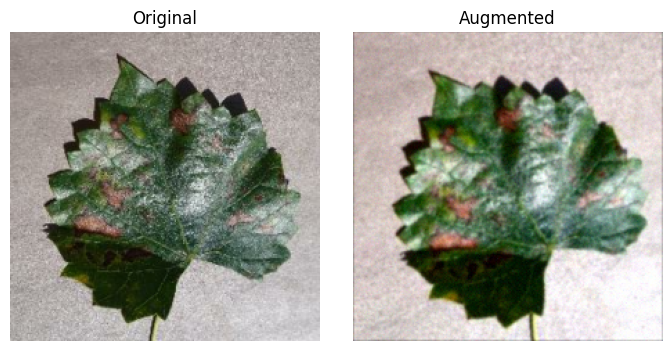

In [23]:
sample = train_df.sample(1, random_state=SEED).iloc[0]
original = load_rgb_image(sample["resolved_image_path"])
augmented = augment_image(original)

print("Class:", sample["label"])
print("Image shape:", augmented.shape)
print("Pixel range:", float(tf.reduce_min(augmented)), "to", float(tf.reduce_max(augmented)))

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(original.numpy())
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(augmented.numpy())
axes[1].set_title("Augmented")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 7. Before-and-after grid

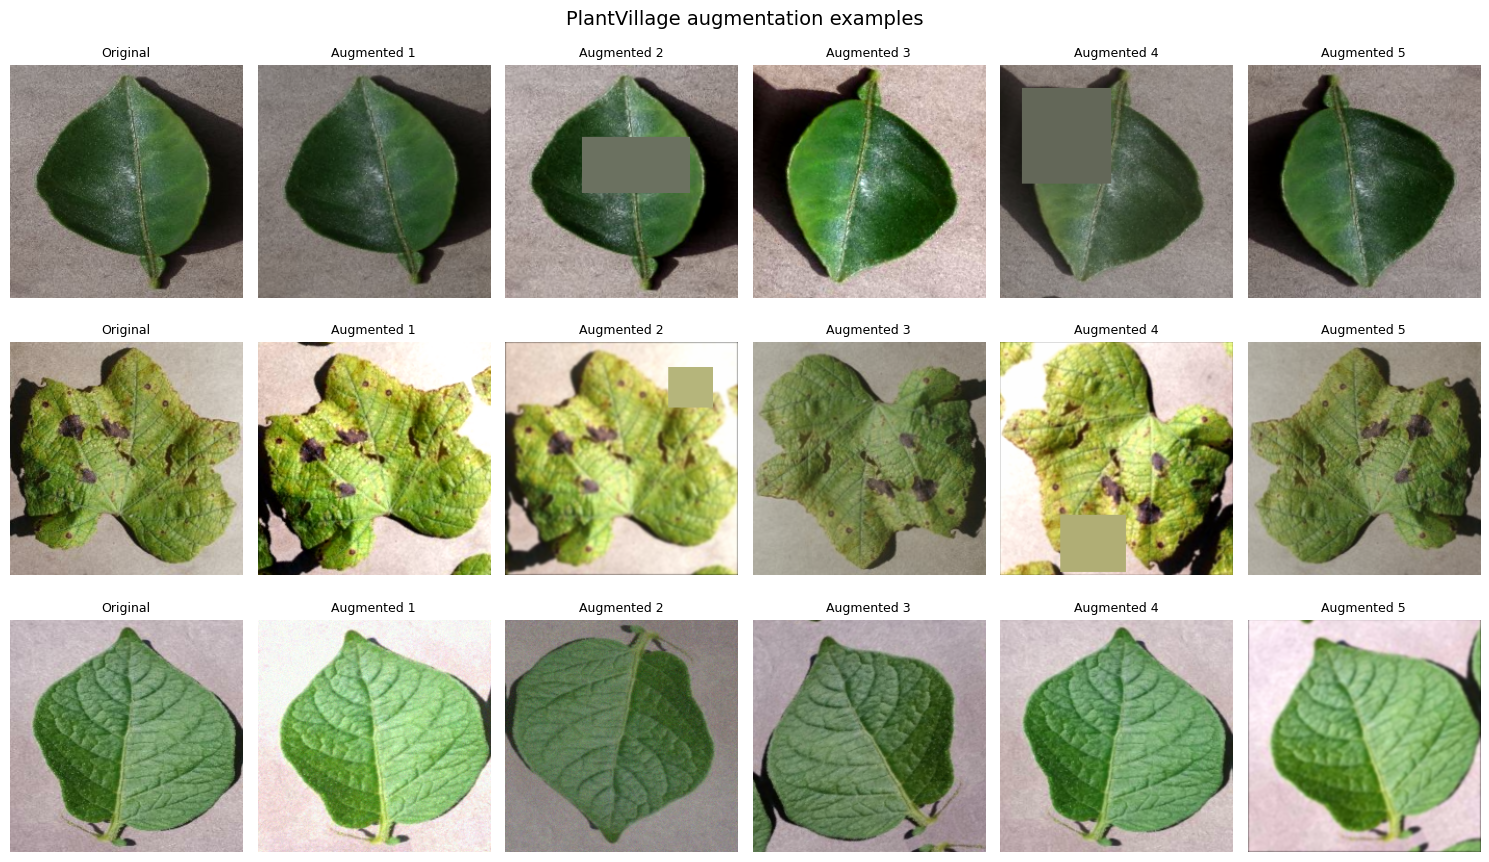

Saved: /kaggle/working/augmentation_handoff/augmentation_before_after_grid.png


In [24]:
class_counts = train_df["label"].value_counts().sort_values(ascending=False)
labels_to_show = [class_counts.index[0], class_counts.index[len(class_counts) // 2], class_counts.index[-1]]
labels_to_show = list(dict.fromkeys(labels_to_show))

fig, axes = plt.subplots(len(labels_to_show), 6, figsize=(15, 3 * len(labels_to_show)))
axes = np.array(axes).reshape(len(labels_to_show), 6)

for row_num, label in enumerate(labels_to_show):
    sample = train_df[train_df["label"] == label].sample(1, random_state=SEED + row_num).iloc[0]
    original = load_rgb_image(sample["resolved_image_path"])
    images = [original] + [augment_image(original) for _ in range(5)]
    titles = ["Original"] + [f"Augmented {i}" for i in range(1, 6)]

    for ax, image, title in zip(axes[row_num], images, titles):
        ax.imshow(np.clip(image.numpy(), 0, 1))
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    axes[row_num, 0].set_ylabel(label, rotation=0, labelpad=75, va="center", fontsize=8)

fig.suptitle("PlantVillage augmentation examples", fontsize=14)
plt.tight_layout()
grid_path = OUTPUT_DIR / "augmentation_before_after_grid.png"
fig.savefig(grid_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", grid_path)

## 8. Individual augmentation effects

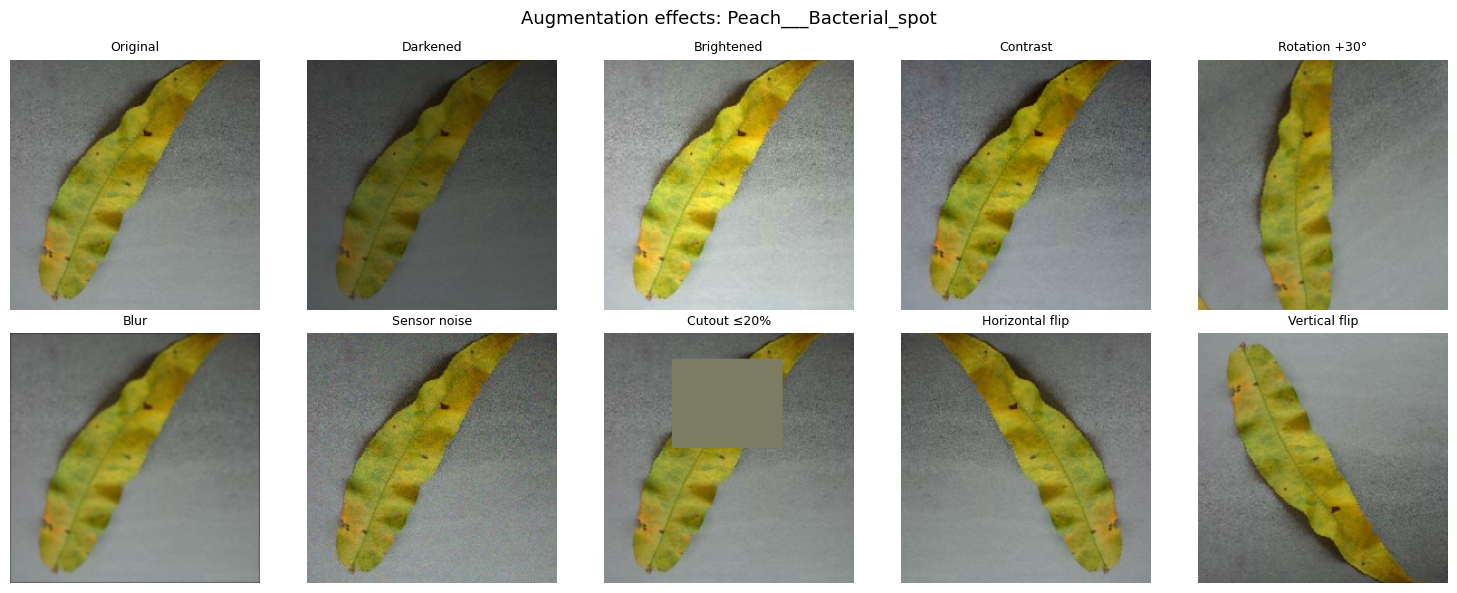

Saved: /kaggle/working/augmentation_handoff/augmentation_effects_showcase.png


In [25]:
sample = train_df.sample(1, random_state=SEED + 10).iloc[0]
image = load_rgb_image(sample["resolved_image_path"])
examples = [
    image,
    tf.clip_by_value(image * 0.60, 0, 1),
    tf.clip_by_value(image * 1.35, 0, 1),
    tf.image.adjust_contrast(image, 1.20),
    _rotate_image(image, 30.0),
    _gaussian_blur(image, 0.9),
    tf.clip_by_value(image + tf.random.normal(tf.shape(image), stddev=0.03), 0, 1),
    _apply_cutout(image),
    tf.image.flip_left_right(image),
    tf.image.flip_up_down(image),
]
titles = ["Original", "Darkened", "Brightened", "Contrast", "Rotation +30°", "Blur", "Sensor noise", "Cutout ≤20%", "Horizontal flip", "Vertical flip"]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, example, title in zip(axes.ravel(), examples, titles):
    ax.imshow(np.clip(example.numpy(), 0, 1))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.suptitle(f"Augmentation effects: {sample['label']}", fontsize=13)
plt.tight_layout()
effects_path = OUTPUT_DIR / "augmentation_effects_showcase.png"
fig.savefig(effects_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", effects_path)

## 9. Check the cutout limit

In [26]:
cutout_areas = []
for _ in range(500):
    mask = _random_cutout_mask(IMG_SIZE, IMG_SIZE)
    cutout_areas.append(float(tf.reduce_mean(tf.cast(mask, tf.float32))))

largest_area = max(cutout_areas)
print(f"Largest sampled cutout: {largest_area:.2%} (limit: 20.00%)")
assert largest_area <= MAX_CUTOUT_AREA + 1e-6

Largest sampled cutout: 19.73% (limit: 20.00%)
